# Lab 11 — Text Analysis and Visualization
**Name / Roll No.:** 24I-2551  |  **Section:** DS-B  |  **Dataset:** `Tweets.csv` (US airline tweets, Feb 2015)

Keep `Tweets.csv` in the same folder as this notebook and run top to bottom. The last section is the one-page brief for the Director.

## Setup — Libraries and dataset

In [1]:
import html
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns

import nltk
from nltk.tokenize import TweetTokenizer
from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from wordcloud import WordCloud
from IPython.display import display

for item in ['stopwords', 'wordnet', 'vader_lexicon', 'averaged_perceptron_tagger_eng']:
    nltk.download(item, quiet=True)

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4), 'figure.dpi': 90})
pd.set_option('display.max_colwidth', 70)
pd.set_option('display.max_columns', 20)
LABELS = ['negative', 'neutral', 'positive']
COLORS = {'negative': '#C44E52', 'neutral': '#8A9299', 'positive': '#319270'}

raw = pd.read_csv('Tweets.csv', dtype={'tweet_id': 'string'})
# One row per tweet_id (keep the most confident label) so no tweet is counted twice.
df = (raw.dropna(subset=['tweet_id', 'text', 'airline_sentiment', 'airline'])
         .sort_values('airline_sentiment_confidence', ascending=False, kind='stable')
         .drop_duplicates('tweet_id', keep='first').sort_index().copy())
df['created_utc'] = pd.to_datetime(df['tweet_created'], utc=True, errors='coerce')
df['retweet_count'] = pd.to_numeric(df['retweet_count'], errors='coerce').fillna(0)

# VADER is run on the RAW tweet text (it uses punctuation, capitals and negation itself).
sia = SentimentIntensityAnalyzer()
def compound(text):
    return sia.polarity_scores(str(text))['compound']
def to_label(score):
    return 'positive' if score >= 0.05 else ('negative' if score <= -0.05 else 'neutral')
df['vader_compound'] = df.text.map(compound)
df['vader_label'] = df.vader_compound.map(to_label)

print(f'Original rows: {len(raw)} | unique tweets used: {len(df)}')

Original rows: 14640 | unique tweets used: 14485


## Part A — Preparing tweet text

### A1 — Tweet features, naive tokenization and how each is treated

In [2]:
tweet_tok = TweetTokenizer(preserve_case=True, reduce_len=False, strip_handles=False)
patterns = {'Handle': r'@\w+', 'Hashtag': r'#\w+', 'URL': r'https?://\S+',
            'Emoji / emoticon': r'[\U0001F300-\U0001FAFF]|[:;]-?[)(DP]',
            'Stretched word': r'([a-z])\1{2,}'}
rows = []
for feature, pat in patterns.items():
    hits = df.text[df.text.map(lambda t: bool(re.search(pat, t, flags=re.I)))]
    example = hits.iloc[0]
    rows.append({'feature': feature, 'tweets containing it': len(hits), 'example': example,
                 'naive regex tokens': re.findall(r'\b\w+\b', example),
                 'tweet-aware tokens': tweet_tok.tokenize(example)})
display(pd.DataFrame(rows))

demo = '@Airline soooo happy :) #NotHappy https://example.com ✈️ 😡'
display(pd.DataFrame({'method': ['Whitespace split', 'Naive word regex', 'TweetTokenizer'],
                      'tokens': [demo.split(), re.findall(r'\b\w+\b', demo), tweet_tok.tokenize(demo)]}))

,feature,tweets containing it,example,naive regex tokens,tweet-aware tokens
0,Handle,14485,@VirginAmerica What @dhepburn said.,"[VirginAmerica, What, dhepburn, said]","[@VirginAmerica, What, @dhepburn, said, .]"
1,Hashtag,2351,@VirginAmerica @virginmedia I'm flying your #fabulous #Seductive s...,"[VirginAmerica, virginmedia, I, m, flying, your, fabulous, Seducti...","[@VirginAmerica, @virginmedia, I'm, flying, your, #fabulous, #Sedu..."
2,URL,1163,@VirginAmerica Really missed a prime opportunity for Men Without H...,"[VirginAmerica, Really, missed, a, prime, opportunity, for, Men, W...","[@VirginAmerica, Really, missed, a, prime, opportunity, for, Men, ..."
3,Emoji / emoticon,761,"@VirginAmerica yes, nearly every time I fly VX this “ear worm” won...","[VirginAmerica, yes, nearly, every, time, I, fly, VX, this, ear, w...","[@VirginAmerica, yes, ,, nearly, every, time, I, fly, VX, this, “,..."
4,Stretched word,117,@VirginAmerica I love this graphic. http://t.co/UT5GrRwAaA,"[VirginAmerica, I, love, this, graphic, http, t, co, UT5GrRwAaA]","[@VirginAmerica, I, love, this, graphic, ., http://t.co/UT5GrRwAaA]"


,method,tokens
0,Whitespace split,"[@Airline, soooo, happy, :), #NotHappy, https://example.com, ✈️, 😡]"
1,Naive word regex,"[Airline, soooo, happy, NotHappy, https, example, com]"
2,TweetTokenizer,"[@Airline, soooo, happy, :), #NotHappy, https://example.com, ✈, ️, 😡]"


**What breaks and what I decided** (the naive regex splits links into `https / t / co`, turns `@united` into an ordinary word, glues `#NotHappy` to nothing, and loses emoticons and emoji):

| Feature | Decision | Justification |
|---|---|---|
| Handles (`@united`) | Remove | Every tweet has one (it only says who the tweet is addressed to); it would swamp the word counts. |
| URLs | Remove | Fragments such as `t`, `co` carry no sentiment. |
| Hashtags | Keep the word, drop `#` | `#fail` / `#fabulous` are often the opinion itself. |
| Emoji / emoticons | Keep in the raw text (VADER reads them); leave out of word counts | They carry sentiment, but they are not words for frequency charts. |
| Stretched words (`soooo`) | Reduce to two letters | Merges spelling variants into one vocabulary item. |

Tweets containing each feature: handles 14,485 (all), hashtags 2,351, URLs 1,163, emoji/emoticons 761, stretched words 117.

In [3]:
def strip_noise(text):
    text = html.unescape(str(text))                         # &amp; -> &
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)      # links
    text = re.sub(r'@\w+', ' ', text)                        # handles
    return re.sub(r'#(\w+)', r'\1', text)                   # keep hashtag word

stages = {'1 Raw tweet-aware tokens': df.text.map(tweet_tok.tokenize)}   # every step is stored for the A4 audit
def add_stage(name, fn):
    stages[name] = stages[list(stages)[-1]].map(fn)

stages['2 Remove handles/URLs, decode HTML, strip #'] = df.text.map(lambda t: tweet_tok.tokenize(strip_noise(t)))
add_stage('3 Lowercase', lambda ts: [t.lower() for t in ts])
add_stage('4 Reduce stretched letters', lambda ts: [re.sub(r'([a-z])\1{2,}', r'\1\1', t) for t in ts])
add_stage('5 Keep alphabetic words / contractions', lambda ts: [t for t in ts if re.fullmatch(r"[a-z]+(?:'[a-z]+)?", t)])
word_tokens = stages[list(stages)[-1]]
display(pd.DataFrame({'original': df.text.head(4), 'tokens so far': word_tokens.head(4)}))

,original,tokens so far
0,@VirginAmerica What @dhepburn said.,"[what, said]"
1,@VirginAmerica plus you've added commercials to the experience... ...,"[plus, you've, added, commercials, to, the, experience, tacky]"
2,@VirginAmerica I didn't today... Must mean I need to take another ...,"[i, didn't, today, must, mean, i, need, to, take, another, trip]"
3,"@VirginAmerica it's really aggressive to blast obnoxious ""entertai...","[it's, really, aggressive, to, blast, obnoxious, entertainment, in..."


### A2 — Negation and stop-word sensitivity

In [4]:
standard_stop = set(stopwords.words('english'))
negations = {'no', 'not', 'nor', 'never', 'neither', 'nothing', 'nobody', 'nowhere', 'cannot',
             "can't", "won't", "don't", "didn't", "isn't", "wasn't", "doesn't", "couldn't",
             "wouldn't", "shouldn't", "haven't", "hasn't", "hadn't", "aren't", "weren't", "mustn't"}
final_stop = (standard_stop - negations) | {'rt', 'amp', 'http', 'https', 'co'}
print('Standard list contains not/no/nor:', [w in standard_stop for w in ['not', 'no', 'nor']])
print('Final list contains not/no/nor:   ', [w in final_stop for w in ['not', 'no', 'nor']])

def remove_stops(text, stops):
    return ' '.join(t for t in tweet_tok.tokenize(text) if t.lower() not in stops)

demo2 = pd.DataFrame({'original': ['The service is not good.', 'No help at the airport.',
                                   'The flight was not bad.', 'Neither helpful nor polite.']})
demo2['standard removal'] = demo2.original.map(lambda x: remove_stops(x, standard_stop))
demo2['negation kept'] = demo2.original.map(lambda x: remove_stops(x, final_stop))
for col in ['original', 'standard removal', 'negation kept']:
    demo2[col + ' (VADER)'] = demo2[col].map(compound)
display(demo2)

# Effect on the sentiment results over the whole dataset
inputs = {'Raw tweet text': df.vader_label,
          'Standard stop-word removal': df.text.map(lambda x: to_label(compound(remove_stops(x, standard_stop)))),
          'Negation kept': df.text.map(lambda x: to_label(compound(remove_stops(x, final_stop))))}
display(pd.DataFrame({name: {'accuracy': accuracy_score(df.airline_sentiment, p),
                             'macro F1': f1_score(df.airline_sentiment, p, labels=LABELS, average='macro'),
                             'predictions changed vs raw': int((p != df.vader_label).sum())}
                      for name, p in inputs.items()}).T.round(4))

add_stage('6 Remove stop words (keep negation)', lambda ts: [t for t in ts if t not in final_stop])

Standard list contains not/no/nor: [True, True, True]
Final list contains not/no/nor:    [False, False, False]


,original,standard removal,negation kept,original (VADER),standard removal (VADER),negation kept (VADER)
0,The service is not good.,service good .,service not good .,-0.3412,0.4404,-0.3412
1,No help at the airport.,help airport .,No help airport .,0.1280,0.4019,0.1280
2,The flight was not bad.,flight bad .,flight not bad .,0.4310,-0.5423,0.4310
3,Neither helpful nor polite.,Neither helpful polite .,Neither helpful nor polite .,-0.3252,-0.3252,-0.3252


,accuracy,macro F1,predictions changed vs raw
Raw tweet text,0.5430,0.5106,0.0
Standard stop-word removal,0.4994,0.4776,1395.0
Negation kept,0.5376,0.5049,663.0


Removing the standard stop words deletes `not`, `no` and `nor`, so the meaning flips: *"The service is not good"* scores **−0.34** but becomes `service good` = **+0.44**, and *"not bad"* becomes `bad` = −0.54. Over the whole dataset, VADER accuracy falls from **54.3% to 49.9%** and 1,395 predictions change.

**Final stop-word list:** the standard NLTK list **minus** negations (`no, not, nor, never, neither, nothing, …` and the `n't` contractions), **plus** `rt, amp, http, https, co`. Even with negations kept, the cleaned text scores slightly worse than the raw text (53.8% vs 54.3%), so **sentiment is always scored on the raw tweet**; the cleaned tokens are used only for word counts, TF-IDF and n-grams.

### A3 — Stemming versus lemmatization

In [5]:
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()
def wn_pos(tag):
    return {'J': wordnet.ADJ, 'V': wordnet.VERB, 'R': wordnet.ADV}.get(tag[0], wordnet.NOUN)

tagged = nltk.pos_tag_sents(word_tokens.tolist())                      # tag BEFORE stop-word removal (needs full sentences)
no_stop = stages['6 Remove stop words (keep negation)']
stem_tokens = no_stop.map(lambda ts: [stemmer.stem(t) for t in ts])
lemma_tokens = pd.Series([[lemmatizer.lemmatize(w, wn_pos(p)) for w, p in sent if w not in final_stop]
                          for sent in tagged], index=df.index)
stages['7 POS-aware lemmatization'] = lemma_tokens

vocab_size = lambda s: len({w for ts in s for w in ts})
display(pd.Series({'Before base reduction': vocab_size(no_stop), 'Porter stemming': vocab_size(stem_tokens),
                   'POS-aware lemmatization': vocab_size(lemma_tokens)}, name='unique words').to_frame())

pairs = Counter((w, stemmer.stem(w), lemmatizer.lemmatize(w, wn_pos(p)))
                for sent in tagged for w, p in sent if w not in final_stop)
cmp = pd.DataFrame([(*k, n) for k, n in pairs.items()], columns=['word', 'stem', 'lemma', 'occurrences'])
display(cmp[cmp.stem != cmp.lemma].sort_values('occurrences', ascending=False).head(10).reset_index(drop=True))

,unique words
Before base reduction,10956
Porter stemming,8327
POS-aware lemmatization,9329


,word,stem,lemma,occurrences
0,thanks,thank,thanks,1033
1,service,servic,service,953
2,customer,custom,customer,743
3,us,us,u,669
4,please,pleas,please,560
5,flightled,flightl,flightled,496
6,got,got,get,450
7,airline,airlin,airline,396
8,fly,fli,fly,369
9,trying,tri,try,346


Vocabulary goes from **10,956** words (before) to **8,327** with stemming and **9,329** with lemmatization. Stemming shrinks the vocabulary more, but it **distorts meaning**: `customer → custom`, `service → servic`, which would put the two most important complaint words into unreadable or wrong forms on a chart. Lemmatization keeps real words (`customer`, `service`) and merges true variants (`flights → flight`). It is not perfect either (`us → u`, because the tagger treats the pronoun as a noun; `u` is later removed as filler).

**Decision: lemmatization**, because the output is shown to a non-technical Director, so every word on a chart must be readable and keep its meaning.

### A4 — What each cleaning step costs

In [6]:
airline_words = {'united', 'usairways', 'americanair', 'american', 'airlines', 'airline', 'southwest',
                 'southwestair', 'delta', 'jetblue', 'virgin', 'virginamerica', 'america', 'airways'}
filler = {'u', 'us', 'please', 'im', 'ive', 'youre', 'flightled'}   # 'flightled' is a non-word artifact (see F2)
stages['8 Remove airline names / filler'] = lemma_tokens.map(
    lambda ts: [t for t in ts if t not in airline_words and t not in filler])
df['tokens'] = stages[list(stages)[-1]]
df['clean_text'] = df.tokens.map(' '.join)

audit = []
for name, s in stages.items():
    lengths = s.map(len)
    audit.append({'step': name, 'vocabulary': vocab_size(s), 'total tokens': lengths.sum(),
                  'mean tokens/tweet': lengths.mean(), 'empty tweets': int(lengths.eq(0).sum())})
audit = pd.DataFrame(audit).set_index('step')
audit['vocabulary change'] = audit.vocabulary.diff()
audit['tokens lost'] = -audit['total tokens'].diff()
display(audit.round(2))
display(df.loc[df.clean_text.eq(''), ['text', 'airline_sentiment']].head(4))

,vocabulary,total tokens,mean tokens/tweet,empty tweets,vocabulary change,tokens lost
step,,,,,,
1 Raw tweet-aware tokens,19854,291083,20.10,0,NaN,NaN
"2 Remove handles/URLs, decode HTML, strip #",17205,273512,18.88,0,-2649.0,17571.0
3 Lowercase,14286,273512,18.88,0,-2919.0,-0.0
4 Reduce stretched letters,14254,273512,18.88,0,-32.0,-0.0
5 Keep alphabetic words / contractions,11120,229031,15.81,3,-3134.0,44481.0
6 Remove stop words (keep negation),10956,127399,8.80,24,-164.0,101632.0
7 POS-aware lemmatization,9329,127399,8.80,24,-1627.0,-0.0
8 Remove airline names / filler,9308,124011,8.56,27,-21.0,3388.0


,text,airline_sentiment
666,@united how about 3659 YUL-ORD?,neutral
781,@united you too!,positive
1644,@united now this http://t.co/uygeW2Nosr,negative
1916,@united I6EP18,neutral


Raw → after stop-word removal: vocabulary **19,853 → 10,956**, total tokens **291,084 → 127,399 (−56%)**, mean tweet length **20.1 → 8.8 tokens**, and only **24 tweets** left empty (e.g. *"@united done"*).

- **Step 5 (alphabetic filter)** removed 44,482 tokens, including `!`, `?` and emoji that carry sentiment. This is fine for word charts, and it is the main reason VADER never sees the cleaned text.
- **Stop-word removal** was the costliest step (101,632 tokens), but with negations kept, only 24 tweets became empty, so it did not go too far.
- No step emptied a meaningful share of tweets, so I kept the whole pipeline for counts and n-grams.

## Part B — Words, distinctive vocabulary and phrases

### B1 — Raw dominance and the fix

Tweets containing an airline handle: 99.97%


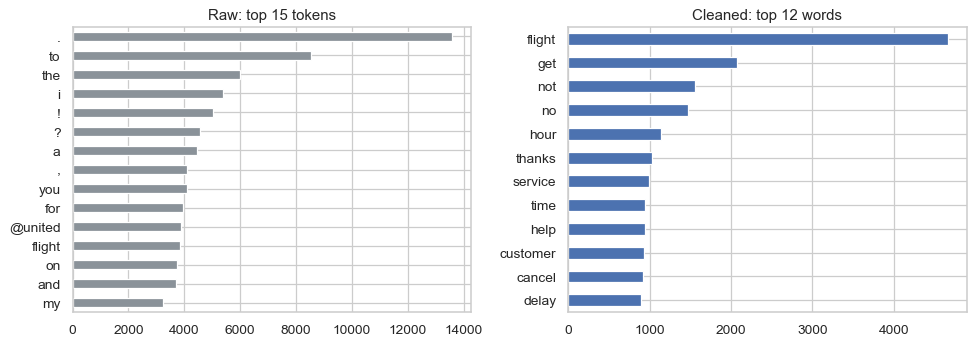

In [7]:
def word_counts(series):
    return Counter(w for ts in series for w in ts)

raw_counts = word_counts(stages['1 Raw tweet-aware tokens'].map(lambda ts: [t.lower() for t in ts]))
clean_counts = word_counts(df.tokens)
handle_pct = 100 * df.text.str.contains(
    r'@(?:united|usairways|americanair|southwestair|jetblue|virginamerica)\b', case=False, regex=True).mean()
print(f'Tweets containing an airline handle: {handle_pct:.2f}%')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
pd.Series(dict(raw_counts.most_common(15))).sort_values().plot.barh(ax=ax[0], color='#8A9299', title='Raw: top 15 tokens')
pd.Series(dict(clean_counts.most_common(12))).sort_values().plot.barh(ax=ax[1], color='#4C72B0', title='Cleaned: top 12 words')
plt.tight_layout(); plt.show()

**Problem:** in the raw data the top tokens are punctuation, filler (`to, the, i, you`) and airline handles, none of which say what customers talk about. **Fix:** remove handles, stop words (keeping negations), airline names and filler, then lemmatize. The cleaned chart shows real topics (`flight, get, not, no, hour, thanks, …`).

**What this says about data collection:** **99.97%** of tweets contain an airline handle. The data was gathered by searching for tweets sent *to* the airlines' accounts, so (1) airline names are an artifact of collection, not a customer topic, and (2) every tweet is addressed to the airline, i.e. people who wanted the airline to read it, not a general sample of passengers.

### B2 — Words that really separate positive from negative (TF-IDF + butterfly chart)

,negative,positive,neg_minus_pos
flight,0.0546,0.0288,0.0258
hour,0.0267,0.0019,0.0248
not,0.0286,0.0064,0.0223
no,0.0276,0.0060,0.0216
hold,0.0193,0.0014,0.0179
cancel,0.0205,0.0028,0.0177
delay,0.0212,0.0039,0.0173
call,0.0181,0.0039,0.0142


,negative,positive,neg_minus_pos
thank,0.0024,0.0897,-0.0872
thanks,0.0075,0.0910,-0.0835
great,0.0026,0.0362,-0.0336
love,0.0023,0.0251,-0.0228
awesome,0.0006,0.0188,-0.0181
best,0.0022,0.0185,-0.0163
much,0.0031,0.0191,-0.0160
appreciate,0.0021,0.0148,-0.0127


Words in BOTH groups' top-15 frequency lists: ['customer', 'flight', 'get', 'help', 'service', 'time']


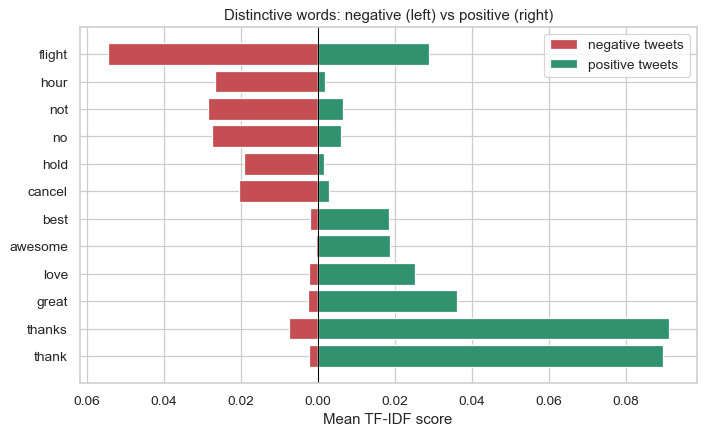

In [8]:
polar = df[df.airline_sentiment.isin(['positive', 'negative'])]
tfidf = TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, min_df=5)
X = tfidf.fit_transform(polar.clean_text)
is_neg = polar.airline_sentiment.eq('negative').to_numpy()
mean_tfidf = pd.DataFrame({'negative': np.asarray(X[is_neg].mean(axis=0)).ravel(),
                           'positive': np.asarray(X[~is_neg].mean(axis=0)).ravel()},
                          index=tfidf.get_feature_names_out())
mean_tfidf['neg_minus_pos'] = mean_tfidf.negative - mean_tfidf.positive
top_neg = mean_tfidf.nlargest(8, 'neg_minus_pos')
top_pos = mean_tfidf.nsmallest(8, 'neg_minus_pos')
display(top_neg.round(4)); display(top_pos.round(4))

# Why raw frequency fails: the most frequent words of both groups largely overlap
group_counts = {s: word_counts(df.loc[df.airline_sentiment.eq(s), 'tokens']) for s in ['negative', 'positive']}
top15 = {s: {w for w, _ in c.most_common(15)} for s, c in group_counts.items()}
print('Words in BOTH groups\' top-15 frequency lists:', sorted(top15['negative'] & top15['positive']))

# Butterfly (back-to-back) chart of the most distinctive words
words = pd.concat([top_pos.head(6), top_neg.head(6)]).sort_values('neg_minus_pos')
y = np.arange(len(words))
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(y, -words.negative, color=COLORS['negative'], label='negative tweets')
ax.barh(y, words.positive, color=COLORS['positive'], label='positive tweets')
ax.set_yticks(y); ax.set_yticklabels(words.index)
ax.axvline(0, color='black', lw=0.8)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{abs(v):.2f}'))
ax.set_xlabel('Mean TF-IDF score'); ax.set_title('Distinctive words: negative (left) vs positive (right)')
ax.legend(); plt.tight_layout(); plt.show()

Most-frequent-word lists are almost the same for both groups (the overlap is printed above) because common words such as `flight`, `get`, `not`, `thanks` appear everywhere, so **raw frequency cannot separate the groups**. TF-IDF down-weights words that appear in many tweets and keeps words concentrated in one group. The positive side is clear: **thank, thanks, great, love, awesome, best**. The negative side (left of the butterfly chart) is made of problem words, i.e. things that went wrong, which is what the Director needs to see.

### B3 — Phrases: bigrams, trigrams, operational problems and a flipped pair

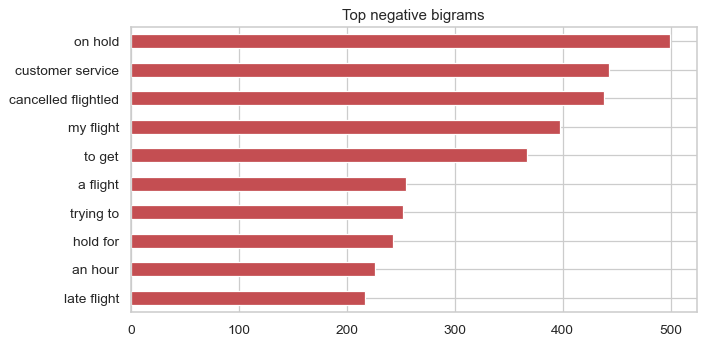

,count
on hold for,233
been on hold,163
was cancelled flightled,94
on the phone,85
i need to,69
your customer service,69
over an hour,68
on the plane,67


,problem phrase,negative tweets,example
0,Cancelled flight,295,@VirginAmerica I have no interesting flying with you after this. I...
1,Lost luggage,69,@VirginAmerica everything was fine until you lost my bag
2,On hold,484,"@VirginAmerica Hi, Virgin! I'm on hold for 40-50 minutes -- are th..."


,negative tweets containing a flipped pair
1082,"@united since bulkhead seats cannot have bags on floor, why don't ..."
1222,@united space. Doctors' notes and everything. And on my first trip...
1478,@united that's not good enough for all of us affected by the awful...


,text,VADER
0,good,0.4404
1,not good,-0.3412
2,happy,0.5719
3,not happy,-0.4585


In [9]:
neg_idx = df.airline_sentiment.eq('negative')
neg_docs = word_tokens[neg_idx].map(' '.join)        # stop words kept so we do not invent phrases across removed words

def ngram_counts(docs, n):
    cv = CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, ngram_range=(n, n), min_df=3)
    m = cv.fit_transform(docs)
    return pd.Series(np.asarray(m.sum(axis=0)).ravel(), index=cv.get_feature_names_out()).sort_values(ascending=False)

def has_content(phrase):                              # drop phrases made only of stop words / airline names
    return any(w not in standard_stop and w not in airline_words for w in phrase.split())

bigrams = ngram_counts(neg_docs, 2); bigrams = bigrams[[has_content(p) for p in bigrams.index]]
trigrams = ngram_counts(neg_docs, 3); trigrams = trigrams[[has_content(p) for p in trigrams.index]]
bigrams.head(10).sort_values().plot.barh(color=COLORS['negative'], title='Top negative bigrams')
plt.tight_layout(); plt.show()
display(trigrams.head(8).to_frame('count'))

negative_text = df.loc[neg_idx, 'text']
operational = {'Cancelled flight': r'\b(?:cancelled|canceled) flights?\b|\bflights? (?:was |is |got |has been )?(?:cancelled|canceled)\b',
               'Lost luggage': r'\blost (?:my |our |the )?(?:luggage|bags?|baggage)\b',
               'On hold': r'\bon hold\b'}
ev = []
for phrase, pat in operational.items():
    m = negative_text.str.contains(pat, case=False, regex=True)
    ev.append({'problem phrase': phrase, 'negative tweets': int(m.sum()), 'example': negative_text[m].iloc[0] if m.any() else ''})
display(pd.DataFrame(ev))

flip = negative_text.str.contains(r'\bnot (?:good|happy|helpful|impressed|pleased)\b', case=False, regex=True)
display(negative_text[flip].head(3).to_frame('negative tweets containing a flipped pair'))
display(pd.DataFrame({'text': ['good', 'not good', 'happy', 'not happy']}).assign(
    VADER=lambda d: d.text.map(compound)))

- **Operational problems a single word would hide:** **"on hold"** (484 negative tweets, a phone-support / waiting problem), **"cancelled flight"** (295) and **"lost luggage"** (69). A single word like `hold` or `lost` could mean many things; the pair names the exact problem. `customer service` is also among the top bigrams.
- **A pair that flips its parts:** **"not good" / "not happy"**: `good` (+0.44) and `happy` (+0.57) are positive words, but the pairs score −0.34 and −0.46.
- *Caution:* some phrase counts (e.g. "cancelled flight") may be inflated by a text artifact in this dataset; see Insight F2.

### B4 — Word cloud or bar chart for the Director?

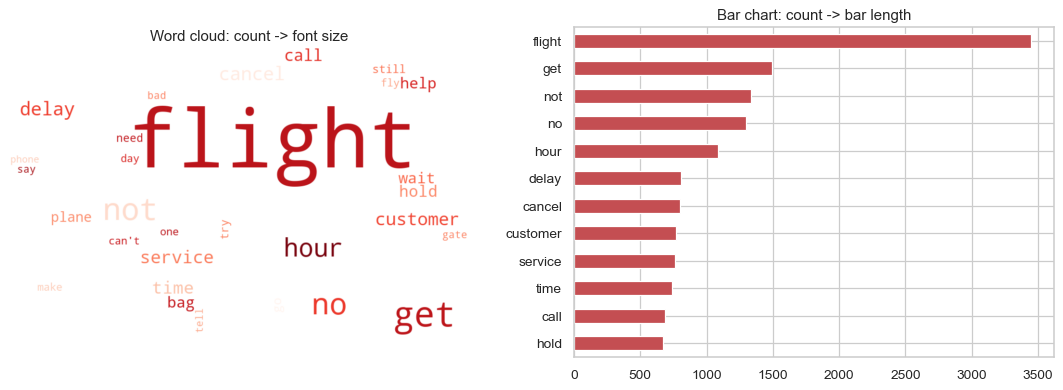

In [10]:
matched = dict(group_counts['negative'].most_common(30))
cloud = WordCloud(width=1000, height=600, background_color='white', colormap='Reds',
                  random_state=11, collocations=False, relative_scaling=1).generate_from_frequencies(matched)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].imshow(cloud, interpolation='bilinear'); ax[0].axis('off'); ax[0].set_title('Word cloud: count -> font size')
pd.Series(matched).nlargest(12).sort_values().plot.barh(ax=ax[1], color=COLORS['negative'], title='Bar chart: count -> bar length')
plt.tight_layout(); plt.show()

**I would show the Director the bar chart.** In the bar chart a word's count becomes a bar **length** on a shared axis, so the Director can rank words and see how much bigger one is than another. In the cloud a count becomes a font **size**, but we read area, not size: long words look bigger than short ones with the same count, placement is random, and there is no scale, so the exact order of the middle words cannot be read. The cloud is fine as a cover image for the overall mood; the bar chart is the evidence.

## Part C — Lexicon sentiment (VADER) versus human labels

### C1 — Agreement with human labels

VADER accuracy: 54.3% | macro F1: 0.511 | always-guess-negative baseline: 62.7%


,precision,recall,f1-score,support
negative,0.898,0.497,0.640,9083.000
neutral,0.386,0.429,0.406,3068.000
positive,0.337,0.872,0.486,2334.000
accuracy,0.543,0.543,0.543,0.543
macro avg,0.540,0.599,0.511,14485.000
weighted avg,0.699,0.543,0.566,14485.000


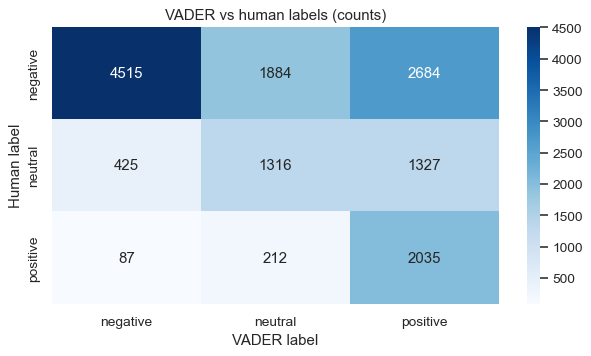

In [11]:
y_true, y_pred = df.airline_sentiment, df.vader_label
print(f'VADER accuracy: {accuracy_score(y_true, y_pred):.1%} | macro F1: {f1_score(y_true, y_pred, labels=LABELS, average="macro"):.3f}'
      f' | always-guess-negative baseline: {y_true.eq("negative").mean():.1%}')
display(pd.DataFrame(classification_report(y_true, y_pred, labels=LABELS, output_dict=True, zero_division=0)).T.round(3))
cm = confusion_matrix(y_true, y_pred, labels=LABELS)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=LABELS, yticklabels=LABELS)
plt.xlabel('VADER label'); plt.ylabel('Human label'); plt.title('VADER vs human labels (counts)'); plt.show()

VADER agrees with the humans on **54.3%** of the 14,485 tweets (macro F1 0.51), **lower than simply guessing "negative" every time (62.7%)**. By class:

- **Negative:** precision is high (0.90) but recall is only **0.50**: it misses half of the real complaints.
- **Positive:** recall is high (0.87) but precision is only **0.34**: it calls many neutral/negative tweets positive (polite words, sarcasm).
- **Neutral** is the hardest class (F1 0.41).

**What the overall figure hides:** the 54% average mixes a tool that finds only half of the complaints with one that over-reports positives. For a customer-complaint use case, the missed negatives (4,568 tweets, see E3) are the number that matters.

### C2 — Where the tool and humans disagree most, and the largest cause

,text,airline_sentiment,vader_compound,distance
5947,@SouthwestAir Report was filed but would like to support some acti...,negative,0.9716,1.9716
2437,@united What a really GREAT &amp; FLATTERING story about you! You ...,negative,0.9467,1.9467
7244,@JetBlue not an issue but I think training &amp; information would...,negative,0.9331,1.9331
2421,@united Just let the employees know that good service and a kind a...,negative,0.9300,1.9300
1740,@United Personal Device Entertainment system is great but with app...,negative,0.9169,1.9169
752,@united The bright side would be keeping the promise that was made...,negative,0.9169,1.9169


,reviewed errors
cause,
Sarcasm,13
Mixed feelings / positive politeness,11
Domain / implicit disruption,6
Context / uncertain label,4
Negation / informal spelling,3
Airline-target mismatch,3


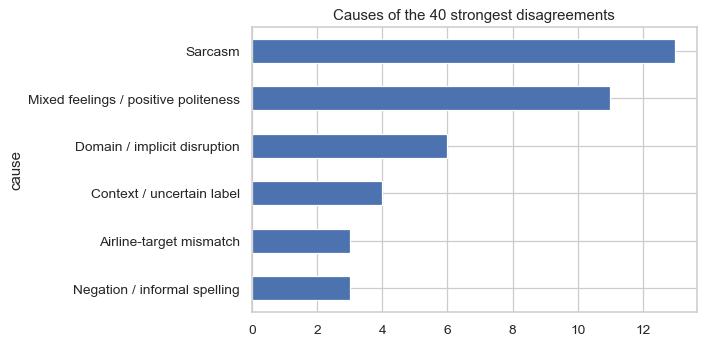

4568 human-negative tweets were missed; 29.0% contain a disruption word.


,VADER lexicon valence (0 = not in lexicon)
delayed,-0.9
cancelled,-1.0
canceled,0.0
stranded,0.0
hold,0.0


,accuracy,negative recall,macro F1
Original VADER,0.543,0.497,0.511
VADER + airline words,0.562,0.531,0.524


In [12]:
dis = df[df.vader_label != df.airline_sentiment].copy()
target = dis.airline_sentiment.map({'negative': -1, 'neutral': 0, 'positive': 1})
dis['distance'] = (dis.vader_compound - target).abs()
worst = dis.sort_values(['distance', 'tweet_id'], ascending=[False, True]).head(40).copy()
display(worst[['text', 'airline_sentiment', 'vader_compound', 'distance']].head(6))

# I read these 40 strongest disagreements and assigned each one a cause (by tweet_id).
review_groups = {
 'Domain / implicit disruption': ['568466642193104897', '570285070184898561', '567742500366872576', '568491765910659072', '569333553705693184', '567857402340450305'],
 'Context / uncertain label': ['569208751972065280', '567786135904980993', '568964010101514240', '569595333899997185'],
 'Mixed feelings / positive politeness': ['569835633147056128', '569215779830280192', '569608866138173440', '570100214733737985', '569936580883783680', '567755768037130241', '570262424038699008', '569202278298755072', '569249933271965696', '568326927695491072', '568129909408841728'],
 'Sarcasm': ['569759999083171840', '569514001450672128', '568769373122342912', '569634729324122112', '569661509988708352', '569698504467021824', '569704219315318784', '569930403106172928', '569904406285516800', '569907965223763970', '567791019086065664', '568585196699664384', '568790707470790656'],
 'Negation / informal spelling': ['569630987858132992', '569682454757257216', '569709246150893568'],
 'Airline-target mismatch': ['569951438329085952', '570151703410053120', '569978748780421121']}
cause_of = {tid: cause for cause, ids in review_groups.items() for tid in ids}
worst['cause'] = worst.tweet_id.map(cause_of)
cause_counts = worst.cause.value_counts()
display(cause_counts.to_frame('reviewed errors'))
if len(cause_counts):
    cause_counts.sort_values().plot.barh(color='#4C72B0', title='Causes of the 40 strongest disagreements')
    plt.tight_layout(); plt.show()

# How widespread are airline-specific words among ALL negative tweets VADER missed?
missed = df[(df.airline_sentiment == 'negative') & (df.vader_label != 'negative')]
disruption = r'\b(?:delay\w*|cancel\w*|flightled|stranded|stuck|hold|rebook\w*|tarmac|lost|waiting|hours?)\b'
print(f'{len(missed)} human-negative tweets were missed; {missed.text.str.contains(disruption, case=False, regex=True).mean():.1%} contain a disruption word.')
display(pd.Series({w: sia.lexicon.get(w, 0.0) for w in ['delayed', 'cancelled', 'canceled', 'stranded', 'hold']},
                  name='VADER lexicon valence (0 = not in lexicon)').to_frame())

# Proposed fix, tested: add airline-specific negative words to a COPY of the lexicon
sia_fix = SentimentIntensityAnalyzer()
sia_fix.lexicon.update({'delayed': -2.0, 'delay': -1.8, 'delays': -1.8, 'cancelled': -2.5, 'canceled': -2.5,
                        'flightled': -2.5, 'stranded': -2.5, 'rebooked': -1.0, 'tarmac': -1.0})
fixed = df.text.map(lambda t: to_label(sia_fix.polarity_scores(t)['compound']))
variants = {'Original VADER': df.vader_label, 'VADER + airline words': fixed}
display(pd.DataFrame({n: {'accuracy': accuracy_score(y_true, p),
                          'negative recall': (p[y_true == 'negative'] == 'negative').mean(),
                          'macro F1': f1_score(y_true, p, labels=LABELS, average='macro')}
                      for n, p in variants.items()}).T.round(3))

**Causes (40 strongest disagreements, read by hand):** **sarcasm 13** (largest), mixed feelings / polite words 11, airline-specific words (domain) 6, uncertain label 4, negation / informal spelling 3, wrong airline target 3. Humans label sarcasm as negative; VADER sees words like "great", "thanks", "love".

**Airline words:** VADER scores `delayed` only −0.9, `cancelled` −1.0, and does not know `canceled`, `stranded` at all (0.0). The share of missed negatives that contain such disruption words is printed above.

**Proposed fixes:** (1) add airline-specific negative words to the lexicon (tested above: compare the two rows for negative recall); (2) sarcasm and mixed feelings cannot be fixed with a lexicon, so they need a classifier trained on labelled airline tweets, or a human reader.

### C3 — Three tweets where counting words misleads the tool

In [13]:
constructed = pd.DataFrame([
    ('Sarcasm', 'Wonderful, another cancelled flight. Just what I wanted!', 'negative'),
    ('Domain meaning', 'My suitcase never arrived at the destination.', 'negative'),
    ('Mixed feelings / urgency', 'The crew was lovely and kind, but I am still stranded overnight.', 'negative')],
    columns=['failure mechanism', 'text', 'intended sentiment'])
constructed['word-count sum'] = constructed.text.map(
    lambda t: sum(sia.lexicon.get(w.lower(), 0) for w in tweet_tok.tokenize(t)))
constructed['VADER compound'] = constructed.text.map(compound)
constructed['VADER label'] = constructed['VADER compound'].map(to_label)
display(constructed)
display(pd.Series({w: sia.lexicon.get(w, 0.0) for w in ['wonderful', 'wanted', 'cancelled', 'never', 'stranded', 'lovely', 'kind']},
                  name='VADER lexicon valence').to_frame())

,failure mechanism,text,intended sentiment,word-count sum,VADER compound,VADER label
0,Sarcasm,"Wonderful, another cancelled flight. Just what I wanted!",negative,1.7,0.4574,positive
1,Domain meaning,My suitcase never arrived at the destination.,negative,0.0,0.0000,neutral
2,Mixed feelings / urgency,"The crew was lovely and kind, but I am still stranded overnight.",negative,5.2,0.5574,positive


,VADER lexicon valence
wonderful,2.7
wanted,0.0
cancelled,-1.0
never,0.0
stranded,0.0
lovely,2.8
kind,2.4


1. **Sarcasm** — *"Wonderful, another cancelled flight. Just what I wanted!"*: `wonderful` (+) and `wanted` (+) outweigh `cancelled` (−1.0), so the score is **+0.46 → positive**. The tool cannot see that the praise is ironic.
2. **Domain meaning** — *"My suitcase never arrived at the destination."*: not one word is negative (`never` is only a negation marker), so the score is **0.00 → neutral**. The complaint (lost luggage) lives in the meaning, not in any word.
3. **Mixed feelings** — *"The crew was lovely and kind, but I am still stranded overnight."*: `lovely` (+2.8) and `kind` (+2.4) are in the lexicon, but `stranded` is not (0.0), so the score is **+0.56 → positive**, even though this passenger needs urgent help.

### C4 — Label confidence

In [14]:
def metrics(frame):
    return {'tweets': len(frame), 'accuracy': accuracy_score(frame.airline_sentiment, frame.vader_label),
            'macro F1': f1_score(frame.airline_sentiment, frame.vader_label, labels=LABELS, average='macro'),
            'always-negative baseline': frame.airline_sentiment.eq('negative').mean()}
HIGH = 0.9
conf = df.airline_sentiment_confidence
display(pd.DataFrame({'All tweets': metrics(df), f'Confidence >= {HIGH}': metrics(df[conf >= HIGH]),
                      f'Confidence < {HIGH}': metrics(df[conf < HIGH])}).T.round(3))
display(pd.crosstab(df.airline_sentiment, conf >= HIGH, normalize='columns').round(3).rename(columns={False: 'below 0.9', True: 'at least 0.9'}))
dups = raw[raw.tweet_id.duplicated(keep=False)]
conflicting = int((dups.groupby('tweet_id').airline_sentiment.nunique() > 1).sum())
print(f'Tweet IDs that appear more than once with DIFFERENT human labels: {conflicting}')

,tweets,accuracy,macro F1,always-negative baseline
All tweets,14485.0,0.543,0.511,0.627
Confidence >= 0.9,10374.0,0.586,0.529,0.706
Confidence < 0.9,4111.0,0.435,0.435,0.427


airline_sentiment_confidence,below 0.9,at least 0.9
airline_sentiment,,
negative,0.427,0.706
neutral,0.371,0.149
positive,0.202,0.145


Tweet IDs that appear more than once with DIFFERENT human labels: 18


Keeping only labels with confidence ≥ 0.9 (10,374 tweets) raises VADER's accuracy from 54.3% to **58.6%**; on low-confidence labels (4,111 tweets) it falls to **43.5%**. Low-confidence tweets contain far more neutral and positive labels (57% vs 29%), which are the ambiguous ones where **the human annotators themselves disagreed**. Also, the confident subset is 70.6% negative, so the always-negative baseline rises to 70.6% and VADER still loses to it.

**Why it matters:** the human labels are not perfect "ground truth". Part of VADER's "error" is the labels being uncertain, so accuracy figures should be reported with the confidence level of the labels, and 18 tweet IDs even carry conflicting labels across duplicate rows.

## Part D — Airline comparison and action

### D1 — Customer service problem versus operations problem

reason,Bad Flight,Can't Tell,Cancelled Flight,Customer Service Issue,Damaged Luggage,Flight Attendant Complaints,Flight Booking Problems,Late Flight,Lost Luggage,longlines
airline,,,,,,,,,,
American,4.3,10.1,12.3,39.6,0.6,4.3,6.6,12.7,7.7,1.7
Delta,6.7,19.5,5.3,20.8,1.2,6.3,4.6,28.2,6.0,1.5
Southwest,7.6,13.4,13.7,33.0,1.2,3.2,5.1,12.8,7.6,2.4
US Airways,4.6,10.9,8.4,35.8,0.5,5.4,5.4,20.0,6.8,2.2
United,8.2,14.4,6.9,25.9,0.8,6.4,5.5,19.9,10.2,1.8
Virgin America,10.5,12.2,9.9,33.1,2.2,2.8,15.5,9.4,2.8,1.7


family,Customer service,Operations,Other / unclear
airline,,,
American,39.6,33.3,27.1
Delta,20.8,40.6,38.5
Southwest,33.0,35.2,31.8
US Airways,35.8,35.7,28.5
United,25.9,37.9,36.3
Virgin America,33.1,24.3,42.5


family,Customer service,Operations,Other / unclear
airline,,,
American,51.5,36.9,11.6
Delta,20.8,56.8,22.4
Southwest,39.6,45.9,14.4
US Airways,43.6,40.4,16.0
United,28.3,53.2,18.5
Virgin America,36.2,32.8,31.0


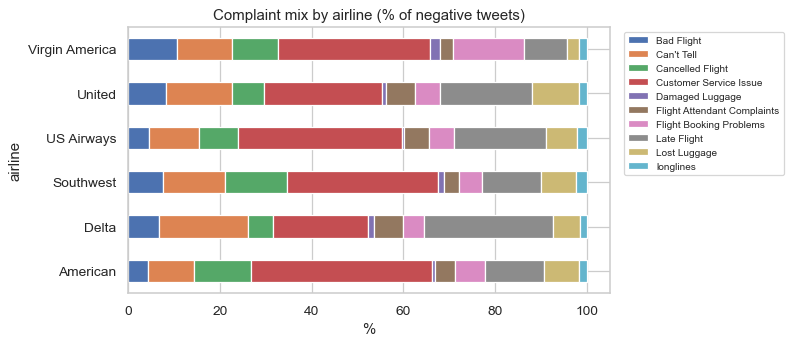

In [15]:
neg = df[df.airline_sentiment.eq('negative')].copy()
neg['reason'] = neg.negativereason.fillna('Unspecified')
reason_share = pd.crosstab(neg.airline, neg.reason, normalize='index') * 100
display(reason_share.round(1))

operations = {'Late Flight', 'Cancelled Flight', 'Lost Luggage', 'Damaged Luggage'}
neg['family'] = np.select([neg.reason.eq('Customer Service Issue'), neg.reason.isin(operations)],
                          ['Customer service', 'Operations'], default='Other / unclear')
display((pd.crosstab(neg.airline, neg.family, normalize='index') * 100).round(1))

sure = neg[(neg.airline_sentiment_confidence >= 0.9) & (neg.negativereason_confidence >= 0.9)]   # reliable labels only
display((pd.crosstab(sure.airline, sure.family, normalize='index') * 100).round(1))

reason_share.plot.barh(stacked=True, figsize=(9, 4))
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.title('Complaint mix by airline (% of negative tweets)'); plt.xlabel('%'); plt.tight_layout(); plt.show()

**The data partly supports the Director.** *Customer service* vs *operations* (late/cancelled flights, lost/damaged bags) shares of each airline's negative tweets:

- **American is the customer-service airline:** 39.6% service vs 33.3% operations (51% vs 37% when only reliable labels are kept).
- **Delta is the operations airline:** 40.6% operations vs 20.8% service (57% vs 21% on reliable labels); late flights alone are 28.2% of its complaints. United also leans to operations (37.9% vs 25.9%).
- **US Airways and Southwest are mixed** (about 36% vs 36%, and 33% vs 35%), so the "one airline = one problem" story is too simple.

### D2 — Raw counts versus sentiment share

,total tweets,negative count,negative share (%),rank by count,rank by share
airline,,,,,
United,3822,2633,68.9,1,3
US Airways,2913,2263,77.7,2,1
American,2604,1865,71.6,3,2
Southwest,2420,1186,49.0,4,4
Delta,2222,955,43.0,5,5
Virgin America,504,181,35.9,6,6


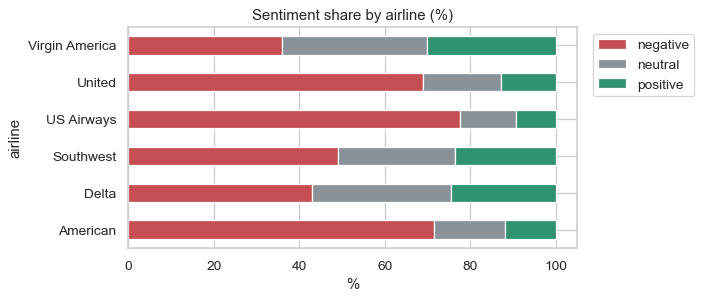

In [16]:
sent = pd.crosstab(df.airline, df.airline_sentiment).reindex(columns=LABELS, fill_value=0)
share = sent.div(sent.sum(axis=1), axis=0) * 100
summary = pd.DataFrame({'total tweets': sent.sum(axis=1), 'negative count': sent.negative, 'negative share (%)': share.negative})
summary['rank by count'] = summary['negative count'].rank(ascending=False, method='min').astype(int)
summary['rank by share'] = summary['negative share (%)'].rank(ascending=False, method='min').astype(int)
display(summary.sort_values('negative count', ascending=False).round(1))
share.plot.barh(stacked=True, color=[COLORS[s] for s in LABELS], figsize=(8, 3.5))
plt.title('Sentiment share by airline (%)'); plt.xlabel('%'); plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left'); plt.tight_layout(); plt.show()

**United** has the most negative tweets (2,633, rank 1) because it also has the most tweets overall, but its negative *share* (68.9%) is only third. **US Airways** has fewer complaints (2,263, rank 2) but the highest share (**77.7%**). **I would report the share**, because it is not driven by how much an airline is mentioned, and quote the count only for workload (how many replies the team must write). Virgin America's share (35.9%) rests on only 504 tweets, so it is less stable.

### D3 — Is negative sentiment spread evenly over time?

,tweets,negative,negative %
day,,,
2015-02-17 00:00:00+00:00,953,552,57.9
2015-02-18 00:00:00+00:00,1416,827,58.4
2015-02-19 00:00:00+00:00,1298,666,51.3
2015-02-20 00:00:00+00:00,1512,849,56.2
2015-02-21 00:00:00+00:00,1418,901,63.5
2015-02-22 00:00:00+00:00,2388,1741,72.9
2015-02-23 00:00:00+00:00,3511,2342,66.7
2015-02-24 00:00:00+00:00,1989,1205,60.6


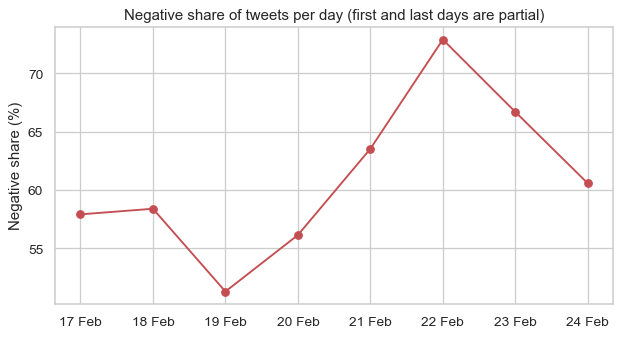

Highest negative share on a complete day: 22 Feb (72.9%)


negativereason,Bad Flight,Can't Tell,Cancelled Flight,Customer Service Issue,Damaged Luggage,Flight Attendant Complaints,Flight Booking Problems,Late Flight,Lost Luggage,longlines
airline,,,,,,,,,,
American,11,24,45,131,0,17,28,42,12,3
Delta,15,32,8,36,0,24,4,84,13,5
Southwest,11,16,37,43,5,1,1,14,14,1
US Airways,13,36,66,208,2,29,17,116,30,19
United,52,63,48,117,2,31,18,101,52,10
Virgin America,1,4,6,10,2,2,5,3,0,1


In [17]:
df['day'] = df.created_utc.dt.floor('D')
daily = df.groupby('day').agg(tweets=('tweet_id', 'size'), negative=('airline_sentiment', lambda s: s.eq('negative').sum()))
daily['negative %'] = daily.negative / daily.tweets * 100
display(daily.round(1))
fig, ax = plt.subplots()
ax.plot(daily.index.strftime('%d %b'), daily['negative %'], marker='o', color=COLORS['negative'])
ax.set_ylabel('Negative share (%)'); ax.set_title('Negative share of tweets per day (first and last days are partial)')
plt.show()

complete = daily.drop([daily.index.min(), daily.index.max()])        # first/last day only partly observed
peak = complete['negative %'].idxmax()
print(f'Highest negative share on a complete day: {peak:%d %b} ({complete.loc[peak, "negative %"]:.1f}%)')
display(pd.crosstab(df[(df.day == peak) & df.airline_sentiment.eq('negative')].airline,
                    df[(df.day == peak) & df.airline_sentiment.eq('negative')].negativereason))

Negative sentiment is **not even**: it hovers around 51–58% on 17–20 Feb, rises to 63.5% on 21 Feb and **72.9% on 22 Feb** (2,388 tweets that day). The table above shows the peak day and which airlines and complaint reasons drove it.

**Can the data say why? No.** It shows *when* and *which complaints*, but it covers only about 7.5 days and contains no weather, schedule or outage data. A cause such as a storm or an IT failure would have to be checked against external records.

### D4 — Which negative tweets should be answered first?

In [18]:
q = neg.copy()
q['immediate need'] = q.text.str.contains(
    r'\b(?:stranded|stuck|urgent|emergency|medical|overnight|insulin|wheelchair)\b|\bmiss(?:ed|ing)? (?:my |our )?connection\b',
    case=False, regex=True)
q['disruption'] = q.reason.isin(['Cancelled Flight', 'Lost Luggage', 'Damaged Luggage'])
q['repeated contact'] = q.text.str.contains(r'\b(?:on hold|hours?|days?|again|still waiting|no response)\b', case=False, regex=True)
q['tier'] = np.select([q['immediate need'], q.disruption | q['repeated contact']], [1, 2], default=3)
q['retweets (capped)'] = q.retweet_count.clip(upper=10)
q = q.sort_values(['tier', 'repeated contact', 'retweets (capped)', 'created_utc'], ascending=[True, False, False, True])
q['label unsure'] = q.airline_sentiment_confidence < 0.9
display(q[['airline', 'text', 'reason', 'tier', 'retweet_count', 'label unsure']].head(6))
display(q.groupby('tier').agg(tweets=('tweet_id', 'size'), unsure_labels=('label unsure', 'sum')))

,airline,text,reason,tier,retweet_count,label unsure
4213,United,@united Stuck in IAD going on 6 hours waiting for a ferry flight f...,Late Flight,1,1,False
2453,United,@united really fucked my day up Hilo to LAX 2hr30min delay because...,Customer Service Issue,1,1,False
6742,Southwest,@SouthwestAir We have been stuck in SJU for several hours and no o...,Late Flight,1,0,False
6578,Southwest,@SouthwestAir you Cancelled Flightled my flight to BNA. I have fli...,Cancelled Flight,1,0,False
4126,United,@united stuck here in IAH waiting on flight 253 to Honolulu for 7 ...,Late Flight,1,0,False
4103,United,@United I'm hoping we don't miss our LAX - ITO connection. Not loo...,Late Flight,1,0,True


,tweets,unsure_labels
tier,,
1,339,45
2,3145,414
3,5599,1297


**Rule:** *Tier 1* = the passenger is stuck or in urgent need (stranded, stuck, medical, missed connection): **339 tweets**. *Tier 2* = a service failure with real cost or a repeat contact (cancelled flight, lost/damaged bag, long waits, "again"): **3,145 tweets**. *Tier 3* = everything else: 5,599 tweets. Inside a tier: repeated contact first, then reach (retweets capped at 10), then the oldest tweet.

**Defense:** urgency to the passenger comes before how popular the tweet is (only 6.6% of negative tweets are retweeted at all, see F3), and the capped retweet count stops one viral tweet from pushing urgent cases down. The rule uses only information in the data and is easy to explain. Its limit: it is keyword-based, so a few tier-1 cases are missed, and some labels are unsure (the `label unsure` column), which is why a human still reads the queue.

## Part E — Reliability and decisions

### E1 — How this dataset could mislead the airline

In [19]:
users = df.groupby('name').size()
evidence = pd.Series({
    'Negative share of all tweets (%)': df.airline_sentiment.eq('negative').mean() * 100,
    'Largest / smallest airline sample': sent.sum(axis=1).max() / sent.sum(axis=1).min(),
    'Tweets from handles posting more than once (%)': df.name.isin(users[users > 1].index).mean() * 100,
    **{f'Missing {c} (%)': df[c].isna().mean() * 100 for c in ['tweet_coord', 'tweet_location', 'user_timezone']}})
display(evidence.round(2).to_frame('value'))

,value
Negative share of all tweets (%),62.71
Largest / smallest airline sample,7.58
Tweets from handles posting more than once (%),67.19
Missing tweet_coord (%),93.05
Missing tweet_location (%),32.36
Missing user_timezone (%),32.97


1. **Self-selected, complaint-addressed sample:** all tweets are sent *to* the airline, and 62.7% are negative. Satisfied passengers who say nothing are invisible, so the data overstates dissatisfaction.
2. **Uneven airline samples:** the largest airline has 7.6× the tweets of the smallest (Virgin America, 504), so shares for small airlines are less stable.
3. **Heavy users:** 67% of tweets come from handles that tweeted more than once, so a few vocal users carry a lot of weight (see F1).
4. **Unknown who and where:** 93% of tweets have no coordinates and about a third have no location or time zone, and Twitter users are younger and more online than the average passenger.

**Findings I trust least:** the **day-by-day pattern** (only about a week of data, no outside records) and the **Virgin America share** (small sample).

### E2 — What would change with data from today

In [20]:
print('First tweet:', df.created_utc.min(), '| Last tweet:', df.created_utc.max())
print('Span (days):', round((df.created_utc.max() - df.created_utc.min()).total_seconds() / 86400, 1), '| airlines:', df.airline.nunique())

First tweet: 2015-02-17 07:36:05+00:00 | Last tweet: 2015-02-24 19:53:37+00:00
Span (days): 7.5 | airlines: 6


All tweets fall within **17–24 Feb 2015** (about 7.5 days). With data from today I would expect:

- **The airline list to change:** US Airways was merged into American and Virgin America was bought by Alaska, so those comparisons could not be repeated as they are.
- **Complaint topics to shift:** app and online check-in problems, extra fees and seating, and automated rebooking, rather than 2015's phone-hold complaints.
- **Where people complain to move:** much support now happens in direct messages, chat and apps, so the public sample would be different, and the platform itself has changed (Twitter is now X).
- **Sentiment tools to behave differently:** modern slang and emoji change how well VADER performs, and the confidence-label results should be re-measured.
- **The airline ranking to change:** the ranking reflects one winter week in 2015, so it should not be assumed to hold.

### E3 — Replace the manual tweet-reading team with the tool?

In [21]:
missed_neg = (df.airline_sentiment == 'negative') & (df.vader_label != 'negative')
display(pd.Series({'Unique tweets': len(df), 'VADER agrees with human': int((df.vader_label == df.airline_sentiment).sum()),
                   'Human-negative tweets missed': int(missed_neg.sum()),
                   'Human-negative tweets missed (%)': 100 * missed_neg.sum() / (df.airline_sentiment == 'negative').sum(),
                   'VADER macro F1': f1_score(df.airline_sentiment, df.vader_label, labels=LABELS, average='macro')}).round(3).to_frame('value'))

,value
Unique tweets,14485.000
VADER agrees with human,7866.000
Human-negative tweets missed,4568.000
Human-negative tweets missed (%),50.292
VADER macro F1,0.511


**Against replacing the team.** VADER agrees with humans on only 7,866 of 14,485 tweets (54.3%, below the 62.7% "always negative" baseline) and **misses 50.3% of the negative tweets** (4,568), failing on sarcasm, mixed feelings and airline words. Automatic replacement would leave half of the complaints unanswered.

**What I would do instead:** use the tool for *triage and trend dashboards* (volume per airline, topic counts, a first sort), with the airline-word lexicon fix from C2, and keep people reading the priority queue from D4, especially tier 1.

## Part F — Three additional insights

### Insight F1 — Complaints come from a small set of repeat posters

In [22]:
neg_users = neg.groupby('name').size()
repeat = neg_users.index[neg_users > 1]
print(f'Negative tweets from handles with 2+ negative tweets: {neg.name.isin(repeat).mean() * 100:.1f}% '
      f'| distinct negative-posting handles: {len(neg_users)} | repeat handles: {len(repeat)}')
first = df.sort_values('created_utc').drop_duplicates(['name', 'airline'], keep='first')
sens = pd.DataFrame({'negative % (all tweets)': share.negative,
                     'negative % (first tweet per handle-airline)': first.groupby('airline').airline_sentiment.apply(lambda s: s.eq('negative').mean() * 100)})
sens['change (points)'] = sens.iloc[:, 1] - sens.iloc[:, 0]
display(sens.round(2))

Negative tweets from handles with 2+ negative tweets: 65.5% | distinct negative-posting handles: 4970 | repeat handles: 1835


,negative % (all tweets),negative % (first tweet per handle-airline),change (points)
airline,,,
American,71.62,69.35,-2.27
Delta,42.98,39.44,-3.54
Southwest,49.01,47.90,-1.10
US Airways,77.69,77.60,-0.09
United,68.89,68.33,-0.56
Virgin America,35.91,35.03,-0.89


| Element | Insight F1 |
|---|---|
| **Observation** | 65.5% of negative tweets come from handles that posted more than one negative tweet (1,835 repeat handles out of 4,970 negative-posting handles). |
| **Evidence** | The counts printed above, and the table comparing negative share with all tweets versus only each handle's first tweet per airline. |
| **Why it matters** | Tweet counts overstate how many different customers are unhappy, and repeat tweets usually mean a problem was not resolved at first contact. |
| **Recommended action** | Group tweets by handle into one customer case, reply once with a real resolution, and track repeat contacts as a service-quality measure. |
| **Confidence and limits** | High for the counts. The airline ranking is stable (the share changes by at most about 3.5 points), but a handle is not always one person, and a "repeat" can also be a customer replying to an answer. |

### Insight F2 — The tweet text contains data artifacts that inflate phrase counts

In [23]:
phrases = ['Flightled', 'Cancelled Flight', 'Late Flight']
flags = pd.DataFrame({p: df.text.str.contains(p, case=False, regex=False) for p in phrases})
display(pd.DataFrame({'tweets': flags.sum(), '% of all tweets': flags.mean() * 100}).round(2))
display(df.loc[flags.Flightled, ['text', 'airline_sentiment', 'negativereason']].head(4))

,tweets,% of all tweets
Flightled,491,3.39
Cancelled Flight,999,6.90
Late Flight,447,3.09


,text,airline_sentiment,negativereason
92,@VirginAmerica I like the TV and interesting video . Just disappoi...,negative,Cancelled Flight
129,@VirginAmerica is flight 882 Cancelled Flightled and what do I do ...,neutral,NaN
133,@VirginAmerica @ChrysiChrysic your assistance yesterday when u Can...,negative,Cancelled Flight
154,@VirginAmerica - Is Flight 713 from Love Field to SFO definitely ...,neutral,NaN


| Element | Insight F2 |
|---|---|
| **Observation** | The text field contains a non-word, "Flightled", in 491 tweets (3.4%), and the capitalised strings "Cancelled Flight" (999 tweets) and "Late Flight" (447), which look like complaint labels rather than customer wording. |
| **Evidence** | The counts and example tweets printed above (e.g. *"flight 882 Cancelled Flightled"*). |
| **Why it matters** | Phrase and word counts (and the cancellation numbers in B3) can partly reflect a data-processing artifact, so a chart could overstate a complaint. |
| **Recommended action** | Check the raw source of the tweets, clean these strings before reporting phrase counts, and rely on the human `negativereason` column for complaint totals. |
| **Confidence and limits** | High that the strings exist; medium on the cause (I infer a processing artifact but cannot confirm it from this file). I excluded `flightled` from the cleaned tokens. |

### Insight F3 — Retweets show very little public amplification

In [24]:
amp = df.groupby('airline_sentiment').agg(tweets=('tweet_id', 'size'), retweeted=('retweet_count', lambda s: s.gt(0).sum()),
                                          total_retweets=('retweet_count', 'sum'), median_retweets=('retweet_count', 'median'))
amp['retweeted share (%)'] = amp.retweeted / amp.tweets * 100
display(amp.reindex(LABELS).round(2))
display(df.nlargest(5, 'retweet_count')[['airline', 'text', 'airline_sentiment', 'retweet_count']])

,tweets,retweeted,total_retweets,median_retweets,retweeted share (%)
airline_sentiment,,,,,
negative,9083,595,855,0.0,6.55
neutral,3068,94,189,0.0,3.06
positive,2334,76,164,0.0,3.26


,airline,text,airline_sentiment,retweet_count
11596,US Airways,@USAirways 5 hr flight delay and a delay when we land . Is that ev...,negative,44
11582,US Airways,@USAirways of course never again tho . Thanks for tweetin ur conce...,negative,32
7132,Delta,STOP. USING.THIS.WORD. IF. YOU'RE. A. COMPANY. RT @JetBlue: Our fl...,negative,31
9999,US Airways,@USAirways with this livery back in the day. http://t.co/EEqWVAMmiy,neutral,28
5607,Southwest,@SouthwestAir beautiful day in Seattle! http://t.co/iqu0PPVq2S,positive,22


| Element | Insight F3 |
|---|---|
| **Observation** | Only 6.6% of negative tweets (595 of 9,083) were retweeted at all, versus about 3% of neutral and positive ones; the median is 0. |
| **Evidence** | The amplification table above and the five most-retweeted tweets (the top one has 44 retweets). |
| **Why it matters** | Complaints here are mostly private-to-the-airline, not viral. Ranking replies by popularity would ignore the many urgent tweets nobody shared. |
| **Recommended action** | Rank replies by urgency first (the D4 tiers) and use retweets only as a capped tie-breaker; watch separately for the rare viral complaint. |
| **Confidence and limits** | High for this sample. The retweet count was recorded at collection time, so it understates later spread. |

---
# One-Page Brief for the Director of Customer Experience
**Based on 14,485 unique airline tweets, 17–24 Feb 2015  |  Prepared by 24I-2551 (DS-B)**

**1. What customers say.** 63% of tweets are negative. The largest named complaint is **customer service** for American (39.6% of its negative tweets), US Airways (35.8%), Southwest (33.0%) and Virgin America (33.1%); for Delta it is **late flights** (28.2%). Phrases that point to specific problems: **"on hold"** (484 negative tweets), **"cancelled flight"** (295), **"lost luggage"** (69). Praise is short and simple: *thanks, great, love, awesome*.

**2. Can software replace the manual reading? No.** The standard tool (VADER) agrees with human labels on only **54%** of tweets, worse than guessing "negative" every time (63%), and it **misses half (50%) of the real complaints**. It fails on sarcasm, mixed feelings and words like "cancelled" or "stranded". Use it to count and sort, not to decide.

**3. How we compare, and where to act first.**

| Airline | Negative share | Main complaint type |
|---|---|---|
| US Airways | 77.7% | mixed (service = operations) |
| American | 71.6% | customer service (40% vs 33% operations) |
| United | 68.9% | operations (38% vs 26% service) |
| Southwest | 49.0% | mixed |
| Delta | 43.0% | operations (41% vs 21% service) |
| Virgin America | 35.9% (only 504 tweets) | other / unclear |

Your hunch is partly right: American leans to service problems and Delta to operations, but US Airways and Southwest do not fit either story.

**Recommended actions**
1. **Answer first** the 339 tweets where passengers are stranded or in urgent need, then cancellations, lost bags and repeat contacts (3,145 tweets).
2. **Fix the support channel** at American and US Airways (hold times, clear rebooking information).
3. **Treat repeat posters as one case:** 65% of negative tweets come from people who tweeted negatively more than once, which suggests unresolved problems.
4. **Keep people in the loop:** use software for dashboards and triage only.

**Limits.** One week of Twitter data addressed to the airlines (self-selected, 93% without location, uneven airline samples); the rise to 72.9% negative on 22 Feb cannot be explained without weather or operations records. I trust the day-by-day pattern and the Virgin America figure least.